## Polynomial Regression - Single Feature

This notebook is designed to implement Polynomial Regression with a single feature. Takes student performance data and attempts to predict performance based on single feature.

Dataset: https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression/data

Shoutout: https://github.com/TempeHS/Machine_Learning_OOP_Implementation_Examples/

Note: The data set was truncated to 100 rows make visualisations clearer

Feature: Previous Scores\
Label  : Performance index 10-100 (higher = better) 

## Step 0) Import modules

Import the required modules our notebook

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error 

## Step 1) Load student performance from CSV

Load the data stored in student_performance_trunk.csv file into a Pandas DataFrame.

x_series and y_series are used to simplify variables throughout the notebook.

In [2]:
student_results = pd.read_csv('datasets/student_performance_updated.csv')

x_series = student_results[['Previous Scores']]
y_series = student_results['Performance Index']

## Step 2) Investigate the data

Use the head() and describe() methods of Pandas Dataframes to investigate the data. 

include='all' is used to include text based columns.

In [3]:
# Print the first 20 rows of data
print (student_results.head(20))
# Print an overview of the data
print (student_results.describe(include='all'))

    Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0               8               99                        Yes            9   
1               6               82                         No            4   
2               4               51                        Yes            7   
3               5               52                        Yes            5   
4               5               75                         No            8   
5               5               78                         No            9   
6               7               73                        Yes            5   
7               3               45                        Yes            4   
8               5               77                         No            8   
9               7               89                         No            4   
10              6               91                         No            4   
11              5               79                         No   

## Step 3) View Correlation table

Correlation table allows you to view the r (relationship) values of the table.

r values range from 0 to 1

Higher values indicate a strong correlation between the x and y. 

In [ ]:
student_results.corr(numeric_only=True)

                                  Hours Studied  Previous Scores  Sleep Hours  \
Hours Studied                          1.000000         0.833526    -0.151904   
Previous Scores                        0.833526         1.000000    -0.054697   
Sleep Hours                           -0.151904        -0.054697     1.000000   
Sample Question Papers Practiced       0.017226         0.048812    -0.016740   
Performance Index                      0.769259         0.914700    -0.022805   

                                  Sample Question Papers Practiced  \
Hours Studied                                             0.017226   
Previous Scores                                           0.048812   
Sleep Hours                                              -0.016740   
Sample Question Papers Practiced                          1.000000   
Performance Index                                         0.073857   

                                  Performance Index  
Hours Studied                         

## Step 4) Visualise the previous score vs the performance index

Previous score was picked as the feature because of it's high correlation (step 3) with the performance index.

For this step we'll create a scatter chart to view the relationship between each student's previous score and their performance index.

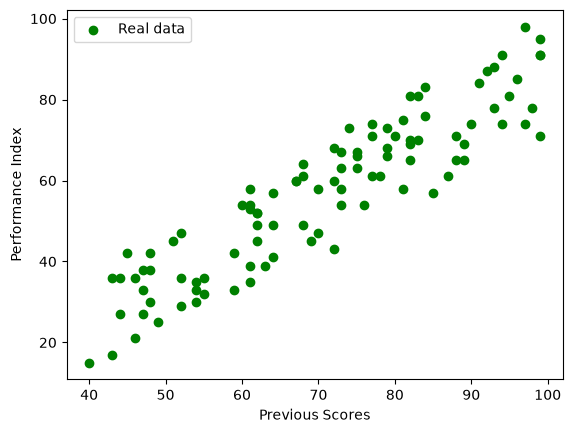

In [5]:
# Create a scatter plot with previous scores as the x axis and performance index on the y axis
plt.scatter(x_series, y_series, label="Real data", color='green')
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.legend()
plt.show()

## Step 5) Train the model

First we create the object to produce a model and extract our feature (x_series) and label (y_series) and then have sklearn create our Polynomial features and Regression model.

In [6]:
model = LinearRegression()

poly = PolynomialFeatures(degree=3, include_bias=False)
poly_features = poly.fit_transform(x_series)

model.fit(poly_features, y_series)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.32, 0.01,-0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.808
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[2615857.31, 2449.85, 2.63]"


## Step 6) Predict a single new value

To test our model, let's have it predict a new performance index. Change the number in the square braces [ ] and view the output. 

In [7]:
new_data = pd.DataFrame({
    'Previous Scores': [67]
})

new_features = poly.fit_transform(new_data)
print ( model.predict(new_features) )

[53.47446832]


## Step 7) View the slope and bias

As part of creating the model, sklearn as determined our best fit slope (intercept) and bias (weight). Let's see what they are.

Due to being a polynomial model, there are multiple slopes in the line. 

In [8]:
slope = model.coef_
bias = model.intercept_

print (f"Slope: {slope}")
print (f"Bias: {bias}")

Slope: [ 3.20599225e-01  1.28341847e-02 -6.91924867e-05]
Bias: -4.807794913465784


Now lets visualise the trend line (aka. the models predicted polynomial regression).

c:\Users\nicho\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


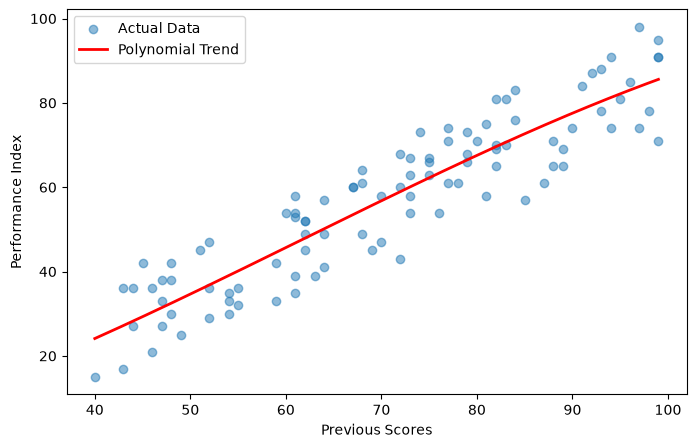

In [9]:
# Sort x values
x_range = np.linspace(
    x_series['Previous Scores'].min(), 
    x_series['Previous Scores'].max(), 
    200
).reshape(-1, 1)

# Transform the smooth x-values using the existing PolynomialFeatures object
x_range_poly = poly.transform(x_range)

# Predict the corresponding y-values
y_pred = model.predict(x_range_poly)

# Plot the scatter points and the polynomial trend line
plt.figure(figsize=(8, 5))
plt.scatter(x_series, y_series, alpha=0.5, label='Actual Data')
plt.plot(x_range, y_pred, color='red', linewidth=2, label='Polynomial Trend')

plt.xlabel('Previous Scores')
plt.ylabel('Performance Index')
plt.legend()
plt.show()

## Step 8) Predict label values

Calculate all the performance index values based on our model. Feeding it just the previous scores.

In [10]:
predictions = model.predict(poly_features)

Now visualise predicted values vs actual values.

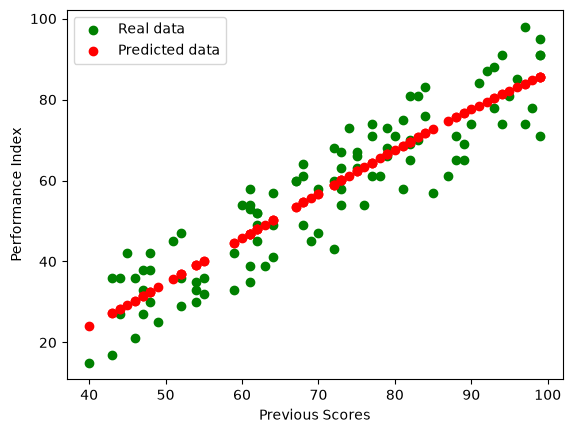

In [11]:
plt.scatter(x_series, y_series, label="Real data", color='green')
plt.scatter(x_series, predictions, label="Predicted data", c='red')
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.legend()
plt.show()

## Step 9) Evaluate the model's overall performance

To calculate the model's performance, we'll look at it's overall score, MAE and MSE. 

Score = 0 to 1. Higher values indicate a more acurate model\
MAE: Mean Absolute Error. Average loss of all predictions\
MSE: Mean Squared Error. Average squared loss of all predictions 

In [12]:
mae = mean_absolute_error(y_true=y_series,y_pred=predictions)
mse = mean_squared_error(y_true=y_series,y_pred=predictions)

print (f"MAE: {mae}")
print (f"MSE: {mse}")

MAE: 6.723768620227711
MSE: 59.620496565654655


## Step 10) Determine Losses

For this final step we'll check the loss for each of our predicted values compared to the original data.

In [13]:
model_loss = pd.DataFrame({
    'Target': y_series,
    'Predicted result': predictions,
    'Loss': abs(model.predict(poly_features).round(2) - y_series)**2
})

print (model_loss)

    Target  Predicted result     Loss
0       91         85.581972  29.3764
1       65         69.627876  21.4369
2       45         35.746027  85.5625
3       36         36.837983   0.7056
4       66         62.238855  14.1376
..     ...               ...      ...
95      30         32.498794   6.2500
96      57         50.140981  47.0596
97      81         82.153740   1.3225
98      36         40.136671  17.1396
99      25         33.576018  73.6164

[100 rows x 3 columns]
